# Лабораторная работа 2. Рекомендательные системы

Цель - сравнить три метода рекомендации 10 исполнителей, которых нет в известной истории пользователя.


In [1]:
from pathlib import Path
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
K = 10
plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 11})
pd.set_option("display.max_columns", 10)

## 1. Датасет и постановка задачи

Используем [Last.fm](https://www.last.fm/) 2K (HetRec 2011) в [фиксированной версии RUCAIBox](https://github.com/RUCAIBox/Social-Datasets/tree/b252d2e8e3a2035f02455b3732589733a0547524/lastfm).
Данные содержат пары «пользователь - исполнитель» и справочник названий и ссылок.
Число прослушиваний `weight` отсутствует; учитываем только факт прослушивания.

Рекомендуем исполнителей. Целевая переменная - бинарный интерес $y_{ui}=1$, если пара есть в данных.
Отсутствие пары означает неизвестный интерес. Релевантные ответы при проверке - исполнители из test.

In [2]:
DATA_DIR = Path("data/lastfm")
DATA_DIR.mkdir(parents=True, exist_ok=True)
BASE_URL = (
    "https://raw.githubusercontent.com/RUCAIBox/Social-Datasets/"
    "b252d2e8e3a2035f02455b3732589733a0547524/lastfm/"
)

for filename in ["lastfm.inter", "lastfm.item", "readme.txt"]:
    path = DATA_DIR / filename
    if not path.exists():
        with urlopen(BASE_URL + filename, timeout=60) as response:
            path.write_bytes(response.read())

interactions = pd.read_csv(DATA_DIR / "lastfm.inter", sep="\t")
interactions.columns = ["user_id", "artist_id"]
artists = pd.read_csv(DATA_DIR / "lastfm.item", sep="\t")
artists.columns = ["artist_id", "name", "url", "picture_url"]

display(interactions.head())
display(artists[["artist_id", "name"]].head())

,user_id,artist_id
0,2,51
1,2,52
2,2,53
3,2,54
4,2,55


,artist_id,name
0,1,MALICE MIZER
1,2,Diary of Dreams
2,3,Carpathian Forest
3,4,Moi dix Mois
4,5,Bella Morte


## 2. Разведочный анализ и качество данных

In [3]:
missing = pd.concat({
    "Взаимодействия": interactions.isna().sum(),
    "Исполнители": artists.isna().sum(),
}).rename("Пропуски").to_frame()
display(missing)

quality = pd.Series({
    "Повторные пары пользователь - исполнитель": interactions.duplicated(["user_id", "artist_id"]).sum(),
    "Повторные ID в справочнике": artists.duplicated("artist_id").sum(),
    "Исполнители без записи в справочнике": (~interactions.artist_id.isin(artists.artist_id)).sum(),
    "Неположительные ID во взаимодействиях": (interactions <= 0).any(axis=1).sum(),
})
display(quality.rename("Количество").to_frame())

assert interactions.notna().all().all()
assert not interactions.duplicated(["user_id", "artist_id"]).any()
assert not artists.duplicated("artist_id").any()
assert interactions.artist_id.isin(artists.artist_id).all()

Пропуски
Взаимодействия user_id             0
               artist_id           0
Исполнители    artist_id           0
               name                0
               url                 0
               picture_url       444

,Количество
Повторные пары пользователь - исполнитель,0
Повторные ID в справочнике,0
Исполнители без записи в справочнике,0
Неположительные ID во взаимодействиях,0


В идентификаторах и названиях пропусков нет; дублей и неизвестных исполнителей нет.
Отсутствуют 444 ссылки на изображения, которые не используются в моделях.
Переименовываем столбцы, сохраняем все строки.

In [4]:
user_activity = interactions.groupby("user_id").size()
artist_popularity = interactions.groupby("artist_id").size()
n_users = len(user_activity)
n_artists = len(artist_popularity)
density = len(interactions) / (n_users * n_artists)

display(pd.Series({
    "Взаимодействия": len(interactions),
    "Пользователи": n_users,
    "Исполнители": n_artists,
    "Разреженность матрицы, %": 100 * (1 - density),
    "Исполнители с одним слушателем, %": 100 * (artist_popularity == 1).mean(),
}).round(3).to_frame("Значение"))

display(pd.DataFrame({
    "Исполнителей у пользователя": user_activity.describe(),
    "Слушателей у исполнителя": artist_popularity.describe(),
}).round(2))

outliers = []
for name, values in [("Длина истории", user_activity), ("Популярность исполнителя", artist_popularity)]:
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers.append({
        "Показатель": name,
        "Нижняя граница IQR": lower,
        "Верхняя граница IQR": upper,
        "Ниже границы": int((values < lower).sum()),
        "Выше границы": int((values > upper).sum()),
    })
display(pd.DataFrame(outliers).set_index("Показатель"))

,Значение
Взаимодействия,92834.000
Пользователи,1892.000
Исполнители,17632.000
"Разреженность матрицы, %",99.722
"Исполнители с одним слушателем, %",60.566


,Исполнителей у пользователя,Слушателей у исполнителя
count,1892.00,17632.00
mean,49.07,5.27
std,5.85,20.62
min,1.00,1.00
25%,50.00,1.00
50%,50.00,1.00
75%,50.00,3.00
max,50.00,611.00


,Нижняя граница IQR,Верхняя граница IQR,Ниже границы,Выше границы
Показатель,,,,
Длина истории,50.0,50.0,63,0
Популярность исполнителя,-2.0,6.0,0,2085


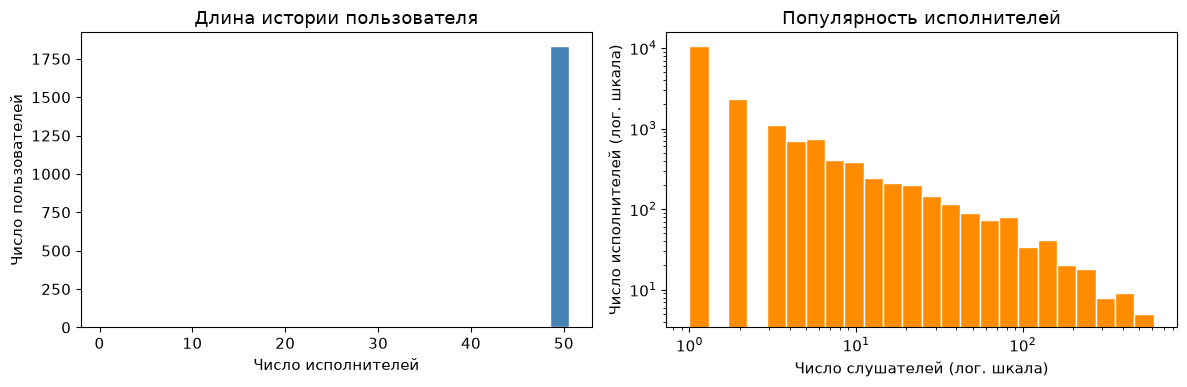

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(user_activity, bins=np.arange(0.5, 52, 2), color="steelblue", edgecolor="white")
axes[0].set(title="Длина истории пользователя", xlabel="Число исполнителей", ylabel="Число пользователей")

bins = np.geomspace(1, artist_popularity.max() + 1, 25)
axes[1].hist(artist_popularity, bins=bins, color="darkorange", edgecolor="white")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set(title="Популярность исполнителей", xlabel="Число слушателей (лог. шкала)", ylabel="Число исполнителей (лог. шкала)")
plt.tight_layout()
plt.show()

Большинство историй содержит 50 наиболее прослушиваемых исполнителей; полная история недоступна.
Медиана популярности - один слушатель, максимум - 611.

Правило 1,5 IQR отмечает 63 истории короче 50 и 2 085 исполнителей с более чем 6 слушателями.
У длины истории IQR равен нулю, поэтому любая история короче 50 выходит за границу.

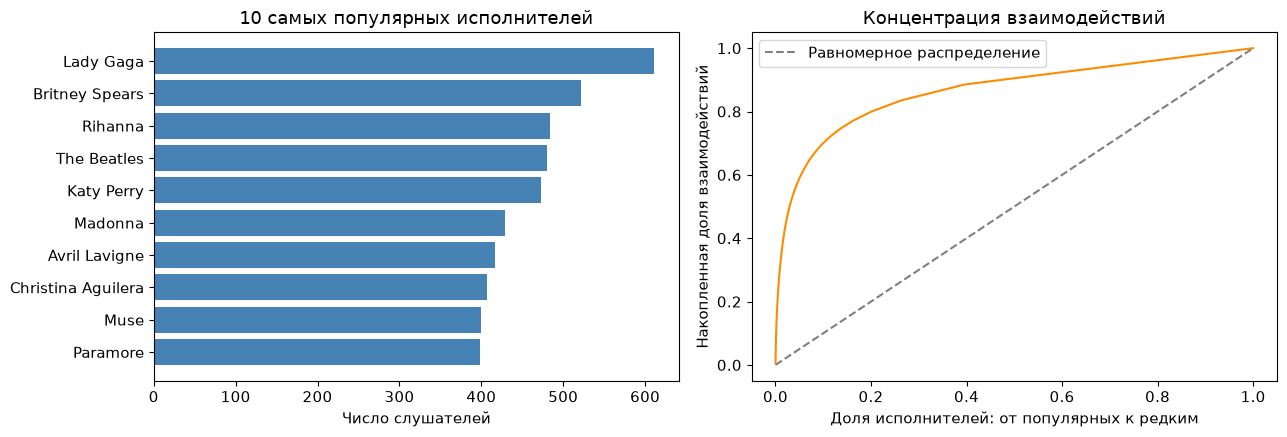

На 10% самых популярных исполнителей приходится 70.0% взаимодействий.


In [6]:
top_artists = (
    artist_popularity.nlargest(10).rename("listeners").reset_index()
    .merge(artists[["artist_id", "name"]], on="artist_id")
)
sorted_popularity = artist_popularity.sort_values(ascending=False).to_numpy()
catalog_share = np.arange(1, n_artists + 1) / n_artists
interaction_share = np.cumsum(sorted_popularity) / len(interactions)
top_10_percent_share = sorted_popularity[:int(0.1 * n_artists)].sum() / len(interactions)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(top_artists.name.iloc[::-1], top_artists.listeners.iloc[::-1], color="steelblue")
axes[0].set(title="10 самых популярных исполнителей", xlabel="Число слушателей")
axes[1].plot(catalog_share, interaction_share, color="darkorange")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Равномерное распределение")
axes[1].set(title="Концентрация взаимодействий", xlabel="Доля исполнителей: от популярных к редким", ylabel="Накопленная доля взаимодействий")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"На 10% самых популярных исполнителей приходится {top_10_percent_share:.1%} взаимодействий.")

Проценты рассчитаны по таблице взаимодействий:

| Показатель | Расчёт |
|---|---|
| Разреженность 99,72% | $100\left(1-\frac{92834}{1892\times17632}\right) \approx 99{,}72\%$ |
| Один слушатель у 60,6% исполнителей | $100\times10679/17632 \approx 60{,}6\%$ |
| На популярные 10% приходится 70% взаимодействий | $100\times65023/92834 \approx 70{,}0\%$; учтены первые 1 763 исполнителя после сортировки по числу слушателей |

Популярность сосредоточена у небольшой части исполнителей. Сравним персональные методы с MostPop.

## 3. Обучающая и тестовая выборки

У каждого пользователя случайно откладываем около 20% исполнителей в test.
Для истории из $n\geq2$ записей число отложенных равно $\max(1,\lfloor0{,}2n\rfloor)$;
единственная запись остаётся в train. Разбиение фиксировано: `SEED = 42`.

В test попало 18 547 строк: $100\times18547/92834 \approx 19{,}98\%$.
В train осталось $92834-18547=74287$ строк.

Времени прослушивания нет. Разбиение оценивает восстановление скрытой истории и не проверяет прогноз будущих событий.
Модели и каталог строятся только по train. Рекомендуем из всего обучающего каталога, исключая известных исполнителей.
Объекты только из test сохраняем в эталонных ответах как недоступные для рекомендации.

In [7]:
rng = np.random.default_rng(SEED)
test_indices = []
for _, history in interactions.groupby("user_id", sort=True):
    if len(history) > 1:
        n_test = max(1, int(0.2 * len(history)))
        test_indices.extend(rng.choice(history.index.to_numpy(), size=n_test, replace=False))

test = interactions.loc[test_indices].copy()
train = interactions.drop(index=test_indices).copy()

train_pairs = pd.MultiIndex.from_frame(train[["user_id", "artist_id"]])
test_pairs = pd.MultiIndex.from_frame(test[["user_id", "artist_id"]])
assert len(train_pairs.intersection(test_pairs)) == 0
assert len(train) + len(test) == len(interactions)
assert set(test.user_id) <= set(train.user_id)

cold_mask = ~test.artist_id.isin(train.artist_id)
display(pd.DataFrame({
    "Выборка": ["train", "test"],
    "Взаимодействия": [len(train), len(test)],
    "Пользователи": [train.user_id.nunique(), test.user_id.nunique()],
    "Исполнители": [train.artist_id.nunique(), test.artist_id.nunique()],
}).set_index("Выборка"))
print(f"Доля test: {len(test) / len(interactions):.2%}")
print(f"Пользователей только в train: {train.user_id.nunique() - test.user_id.nunique()}")
print(f"Исполнителей только в test: {test.loc[cold_mask, 'artist_id'].nunique()}")
print(f"Взаимодействий test с неизвестными исполнителями: {cold_mask.sum()} ({cold_mask.mean():.2%})")

,Взаимодействия,Пользователи,Исполнители
Выборка,,,
train,74287,1892,15415
test,18547,1884,6371


Доля test: 19.98%
Пользователей только в train: 8
Исполнителей только в test: 2217
Взаимодействий test с неизвестными исполнителями: 2331 (12.57%)


In [8]:
user_ids = np.sort(train.user_id.unique())
item_ids = np.sort(train.artist_id.unique())
user_to_index = {user: index for index, user in enumerate(user_ids)}
item_to_index = {item: index for index, item in enumerate(item_ids)}

X = csr_matrix((
    np.ones(len(train), dtype=np.float32),
    (train.user_id.map(user_to_index), train.artist_id.map(item_to_index)),
), shape=(len(user_ids), len(item_ids)))

test_by_user = test.groupby("user_id").artist_id.agg(set)
assert X.nnz == len(train)
assert (X.data == 1).all()
print(f"Обучающая матрица: {X.shape[0]} пользователей x {X.shape[1]} исполнителей")

Обучающая матрица: 1892 пользователей x 15415 исполнителей


## 4. Методы рекомендаций

Все методы используют бинарную матрицу $X$: $X_{ui}=1$ для взаимодействия из train, иначе $0$.

### 4.1. MostPop - популярность

Оценка - число слушателей исполнителя в train: $s_{ui}=\sum_v X_{vi}$, то есть сумма его столбца $X$.
Это базовый метод для проверки пользы персонализации.

In [9]:
popularity = np.asarray(X.sum(axis=0)).ravel()

def mostpop_scores(user_index):
    return popularity

### 4.2. ItemKNN - сходство исполнителей

Косинус между столбцами $X$ измеряет сходство исполнителей по общим слушателям:

$$\operatorname{sim}(i,j)=\frac{X_{:i}^{T}X_{:j}}{\|X_{:i}\|\,\|X_{:j}\|}.$$

Для бинарных данных числитель - число общих слушателей,
знаменатель - корень из произведения чисел слушателей двух исполнителей.
В каждой строке оставляем до 50 других исполнителей с наибольшим положительным сходством.
Матрица $S$ после отбора может быть несимметричной.
Суммируем вклад соседей из истории пользователя: $s_{uj}=\sum_{i:X_{ui}=1} S_{ij}$.

In [10]:
N_NEIGHBORS = 50
similarity = cosine_similarity(X.T, dense_output=False).tocsr()
similarity.setdiag(0)
similarity.eliminate_zeros()
similarity.sort_indices()

for item_index in range(X.shape[1]):
    start, end = similarity.indptr[item_index:item_index + 2]
    if end - start > N_NEIGHBORS:
        values = similarity.data[start:end]
        to_remove = np.argsort(-values, kind="stable")[N_NEIGHBORS:]
        similarity.data[start + to_remove] = 0

similarity.eliminate_zeros()
assert np.all(similarity.diagonal() == 0)
assert np.diff(similarity.indptr).max() <= N_NEIGHBORS

def itemknn_scores(user_index):
    return (X[user_index] @ similarity).toarray().ravel()

### 4.3. SVD - матричное разложение

Разложение $X \approx U_d\Sigma_d V_d^T$, $d=64$, описывает пользователей и исполнителей скрытыми факторами.
Оценку интереса получаем скалярным произведением векторов пользователя и исполнителя.

Используем `TruncatedSVD` без центрирования. Отсутствующие взаимодействия представлены нулями,
хотя отсутствие прослушивания не означает неприязнь.
Число факторов 64 и число соседей ItemKNN 50 заданы заранее, без подбора по test.

In [11]:
N_FACTORS = 64
svd = TruncatedSVD(n_components=N_FACTORS, random_state=SEED)
user_factors = svd.fit_transform(X)

def svd_scores(user_index):
    return user_factors[user_index] @ svd.components_

Выбираем top-10 оценок после исключения train-истории. При равенстве берём меньший `artist_id`.

In [12]:
def top_k(scores, seen_indices, k=K):
    scores = np.asarray(scores, dtype=float).copy()
    scores[seen_indices] = -np.inf
    return np.argsort(-scores, kind="stable")[:k]

assert top_k([10, 9, 3, 2], [0, 1], k=2).tolist() == [2, 3]

## 5. Метрики качества

$R_u$ - список из $K=10$ рекомендаций, $T_u$ - множество исполнителей в test,
$rel_r=1$ для релевантной рекомендации на позиции $r$.

1. Precision@10 - доля попаданий среди рекомендаций:
   $$P@K=\frac{|R_u\cap T_u|}{K}.$$
2. Recall@10 - доля восстановленной test-истории:
   $$R@K=\frac{|R_u\cap T_u|}{|T_u|}.$$
3. NDCG@10 - качество ранжирования с большим весом первых позиций:
   $$DCG@K=\sum_{r=1}^K\frac{rel_r}{\log_2(r+1)},\qquad
   NDCG@K=\frac{DCG@K}{\sum_{r=1}^{\min(K,|T_u|)}1/\log_2(r+1)}.$$
4. Unexpectedness@10 относительно MostPop - доля рекомендаций вне его выдачи:
   $$Unexpectedness@K=\frac{|R_u\setminus M_u|}{K},$$
   где $M_u$ - top-$K$ MostPop с исключением train-истории пользователя.

В проверочном примере ниже $K=3$, попадания стоят на позициях 1 и 3:
$Precision=2/3$, $Recall=2/2=1$.
$DCG=1+1/\log_2 4=1{,}5$, $IDCG=1+1/\log_2 3\approx1{,}631$,
поэтому $NDCG\approx0{,}9197$. Двух рекомендаций нет в MostPop: $Unexpectedness=2/3$.

Все метрики лежат от 0 до 1. Unexpectedness у MostPop равна 0.

In [13]:
def recommendation_metrics(recommended, relevant, mostpop_recommended):
    hits = np.array([item in relevant for item in recommended], dtype=float)
    k = len(recommended)
    discounts = 1 / np.log2(np.arange(2, k + 2))
    ideal_dcg = discounts[:min(k, len(relevant))].sum()
    return {
        f"Precision@{k}": hits.sum() / k,
        f"Recall@{k}": hits.sum() / len(relevant),
        f"NDCG@{k}": (hits * discounts).sum() / ideal_dcg,
        f"Unexpectedness@{k}": (~np.isin(recommended, mostpop_recommended)).mean(),
    }

example_mostpop = [10, 40, 50]
example = recommendation_metrics([10, 20, 30], {10, 30}, example_mostpop)
assert np.isclose(example["Precision@3"], 2 / 3)
assert np.isclose(example["Recall@3"], 1)
assert np.isclose(example["NDCG@3"], 1.5 / (1 + 1 / np.log2(3)))
assert np.isclose(example["Unexpectedness@3"], 2 / 3)

same_as_mostpop = recommendation_metrics([50, 10, 40], {10}, example_mostpop)
assert same_as_mostpop["Unexpectedness@3"] == 0
disjoint = recommendation_metrics([20, 30, 60], {30}, example_mostpop)
assert disjoint["Unexpectedness@3"] == 1

no_hits = recommendation_metrics([10, 20, 30], {99}, example_mostpop)
assert all(no_hits[name] == 0 for name in ["Precision@3", "Recall@3", "NDCG@3"])
assert no_hits["Unexpectedness@3"] == example["Unexpectedness@3"]

## 6. Оценка на test и сравнение

Все методы оцениваем на одном разбиении и каталоге.
Из 1 892 пользователей восемь имеют единственное взаимодействие и остаются только в train;
для оценки остаётся $1892-8=1884$ пользователя.

Каждое значение таблицы - среднее пользовательских метрик:
$\overline m=\frac{1}{1884}\sum_u m_u$.
Для Unexpectedness используем один и тот же список MostPop каждого пользователя.

In [14]:
mostpop_by_user = {}
for user_id in test_by_user.index:
    user_index = user_to_index[user_id]
    seen = X[user_index].indices
    mostpop_by_user[user_id] = item_ids[top_k(mostpop_scores(user_index), seen)]

methods = {
    "MostPop": mostpop_scores,
    "ItemKNN": itemknn_scores,
    "SVD": svd_scores,
}
rows = []

for method_name, score_function in methods.items():
    user_metrics = []
    for user_id, relevant in test_by_user.items():
        user_index = user_to_index[user_id]
        seen = X[user_index].indices
        recommended_indices = top_k(score_function(user_index), seen)
        assert len(recommended_indices) == K
        assert len(np.unique(recommended_indices)) == K
        assert not np.isin(recommended_indices, seen).any()
        recommended = item_ids[recommended_indices]
        metrics = recommendation_metrics(recommended, relevant, mostpop_by_user[user_id])
        if method_name == "MostPop":
            assert metrics[f"Unexpectedness@{K}"] == 0
        user_metrics.append(metrics)

    average_metrics = pd.DataFrame(user_metrics).mean().to_dict()
    rows.append({"Метод": method_name, **average_metrics})

results = pd.DataFrame(rows).set_index("Метод")
assert results.loc["MostPop", f"Unexpectedness@{K}"] == 0
assert results[f"Unexpectedness@{K}"].between(0, 1).all()
display(results.round(4))

,Precision@10,Recall@10,NDCG@10,Unexpectedness@10
Метод,,,,
MostPop,0.0687,0.0694,0.0802,0.0000
ItemKNN,0.1472,0.1494,0.1857,0.7701
SVD,0.1333,0.1363,0.1596,0.9620


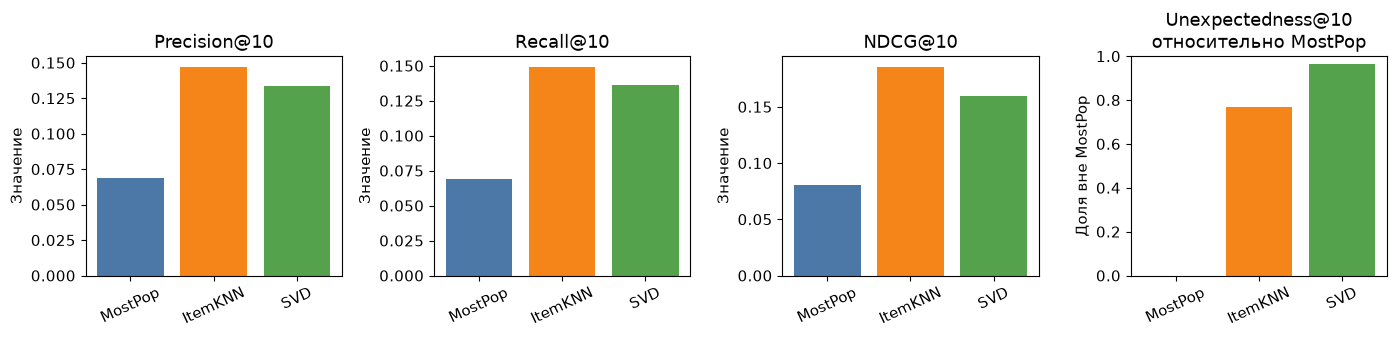

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
colors = ["#4C78A8", "#F58518", "#54A24B"]
for ax, metric in zip(axes, results.columns):
    ax.bar(results.index, results[metric], color=colors)
    ax.set_title("Unexpectedness@10\nотносительно MostPop" if metric == "Unexpectedness@10" else metric)
    ax.set_ylim(bottom=0)
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylabel("Доля вне MostPop" if metric == "Unexpectedness@10" else "Значение")
    if metric == "Unexpectedness@10":
        ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

### Интерпретация результатов

ItemKNN лидирует по Precision@10, Recall@10 и NDCG@10.
В среднем он даёт $10\times0{,}1472\approx1{,}47$ попадания из 10
и восстанавливает $100\times0{,}1494=14{,}94\%$ test-истории.
NDCG@10 равна 0,1857 против 0,0802 у MostPop.
SVD также превосходит MostPop по этим трём метрикам, но уступает ItemKNN.

Unexpectedness переводим в проценты умножением на 100: у SVD 96,20%, у ItemKNN 77,01%.
Большее отличие от MostPop здесь не даёт лучших попаданий.

Холодных исполнителей $17632-15415=2217$: эти ID есть в test, но отсутствуют в train.
На них приходится 2 331 строка test, то есть $100\times2331/18547\approx12{,}57\%$.
Эти взаимодействия остаются непопаданиями, поскольку исполнителей нет в обучающем каталоге.

## 7. Предложения по улучшению и выводы

1. Подобрать число соседей и факторов на validation внутри train.
2. Учесть число прослушиваний из исходного архива.
3. Использовать теги или жанры для редких исполнителей.
4. При наличии дат применить time-split.

На выбранном разбиении по точности и ранжированию предпочтителен ItemKNN.